<a href="https://colab.research.google.com/github/ashrita948/EDA/blob/main/Ashrita_NewYork_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [45]:
# Loading the data set
df = pd.read_csv("/content/AB_NYC_2019.csv")

In [46]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [47]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [49]:
df.duplicated().sum()

np.int64(0)

In [50]:
df.isnull().sum()


,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [51]:
#categorical
df = df.fillna(df.mode().iloc[0])

In [52]:
#numerical
num =  df.select_dtypes(include ='number').columns
df[num] = df[num].fillna(df[num].median())

In [53]:
df.isnull().sum()

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [54]:
df.select_dtypes(include = ["int64","float64"]).columns

Index(['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')

<Axes: xlabel='price', ylabel='Density'>

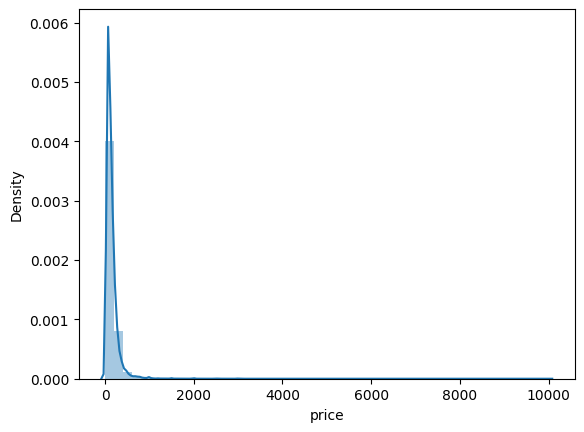

In [55]:
# Univariate Analysis
sns.distplot(df['price'])

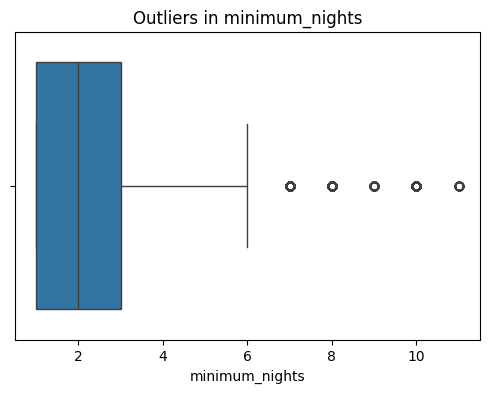

In [86]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["minimum_nights"])
plt.title("Outliers in minimum_nights")
plt.show()

In [57]:
#Outlier treatment
Q1 = df['minimum_nights'].quantile(0.25)
Q3 = df['minimum_nights'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['minimum_nights'] >= lower_bound) & (df['minimum_nights'] <= upper_bound)]

In [58]:
df['minimum_nights'] = df['minimum_nights'].clip(lower_bound, upper_bound)

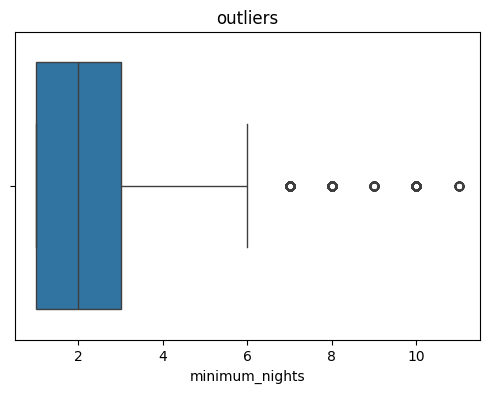

In [85]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["minimum_nights"])
plt.title("outliers")
plt.show()

<Axes: xlabel='availability_365', ylabel='Density'>

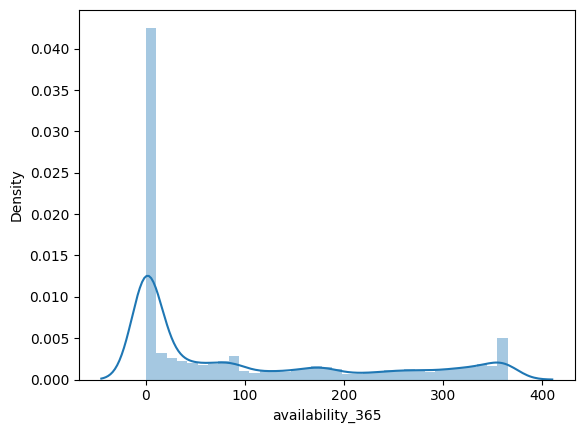

In [60]:
# Univariate Analysis
sns.distplot(df['availability_365'])

<Axes: xlabel='minimum_nights', ylabel='price'>

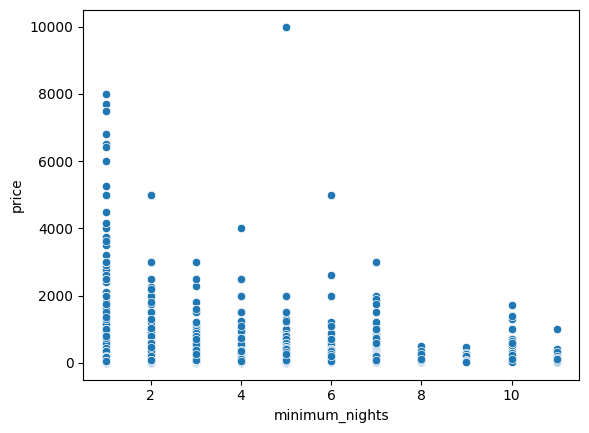

In [88]:
#bivariate analysis
sns.scatterplot(x = 'minimum_nights', y = 'price', data = df)

<Axes: xlabel='minimum_nights', ylabel='availability_365'>

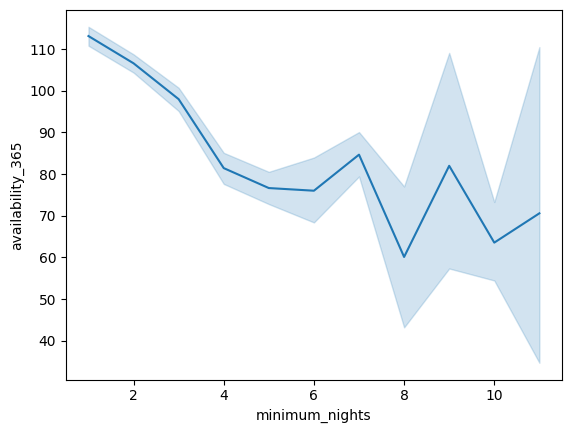

In [62]:
sns.lineplot(x = 'minimum_nights', y = 'availability_365', data = df)

In [63]:
df = df.drop(columns=["name","host_name","last_review"])

In [64]:
#Address High Cardinality
print("Unique neighbourhoods:", df['neighbourhood'].nunique())
print("Unique neighbourhood groups:", df['neighbourhood_group'].nunique())

Unique neighbourhoods: 221
Unique neighbourhood groups: 5


In [65]:
df = df.drop(columns=['neighbourhood'])

In [66]:
# One-Hot Encoding
df = pd.get_dummies(
    df,
    columns=['neighbourhood_group','room_type'],
    drop_first=True,
    dtype=int
)
print(df.head())
print(df.columns.tolist())

     id  host_id  latitude  longitude  price  minimum_nights  \
0  2539     2787  40.64749  -73.97237    149               1   
1  2595     2845  40.75362  -73.98377    225               1   
2  3647     4632  40.80902  -73.94190    150               3   
3  3831     4869  40.68514  -73.95976     89               1   
4  5022     7192  40.79851  -73.94399     80              10   

   number_of_reviews  reviews_per_month  calculated_host_listings_count  \
0                  9               0.21                               6   
1                 45               0.38                               2   
2                  0               0.02                               1   
3                270               4.64                               1   
4                  9               0.10                               1   

   availability_365  neighbourhood_group_Brooklyn  \
0               365                             1   
1               355                             0   
2    

In [67]:
X = df.drop('price', axis=1)

y = df['price']

In [68]:
print(X_train.select_dtypes(include=["object"]).columns)

Index([], dtype='object')


In [69]:
from sklearn.model_selection import train_test_split

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [71]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

In [72]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [73]:
y_pred = model.predict(X_test)

In [74]:
print(y_pred)

[169.57359587 175.03880607 204.93960268 ... 204.2698365  129.99291916
 232.43806278]


In [75]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results)

       Actual   Predicted
23264      79  169.573596
11117     120  175.038806
3100      300  204.939603
1673       50  130.650571
44884     165  317.516378
...       ...         ...
34882     379  277.506597
9429       63   48.270464
17773     113  204.269837
5206      110  129.992919
1717      150  232.438063

[8458 rows x 2 columns]


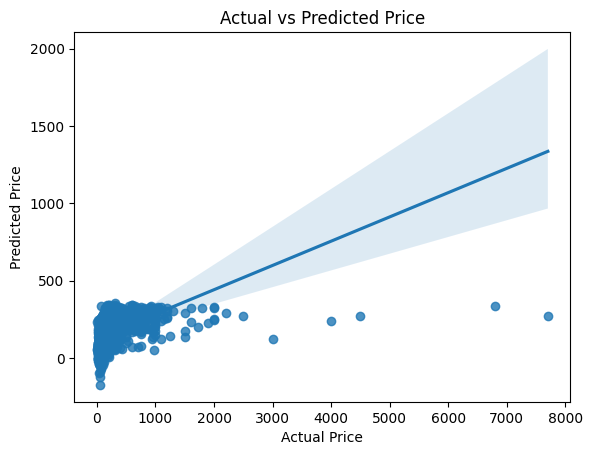

In [76]:
sns.regplot(x = y_test, y = y_pred, data = df)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.show()

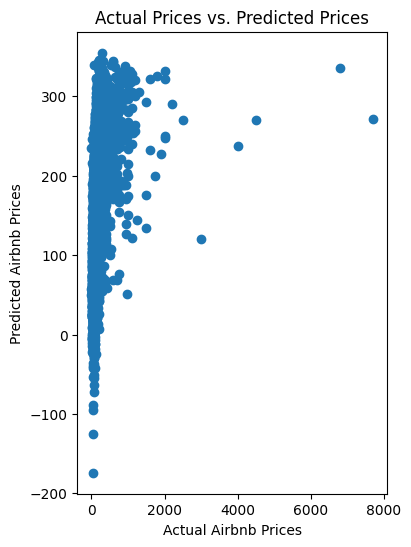

In [77]:
# Scatter plot
plt.figure(figsize=(4, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Airbnb Prices")
plt.ylabel("Predicted Airbnb Prices")
plt.title("Actual Prices vs. Predicted Prices")
plt.show()

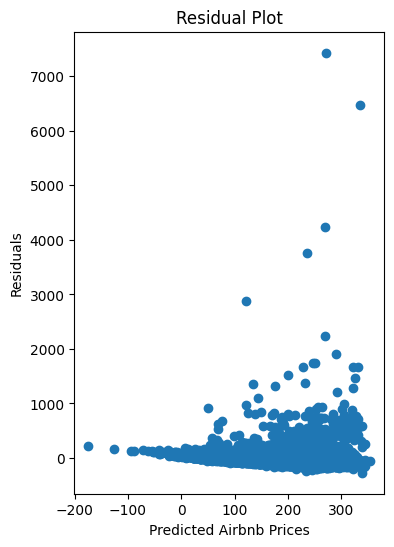

In [78]:
residuals = y_test - y_pred
plt.figure(figsize=(4, 6))
plt.scatter(y_pred, residuals)
plt.xlabel("Predicted Airbnb Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [79]:
print("slope:",model.coef_[0])
print("Intercept:",model.intercept_)

slope: -7.646796448663514e-08
Intercept: -26876.50982458798


In [80]:
r2 = r2_score(y_test, y_pred)
print("R squared:",r2)

R squared: 0.1585534888387986


In [81]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error",mse)

Mean Squared Error 31299.30239009056


In [82]:
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print("Mean Squared Error",rmse)

Mean Squared Error 176.91608855638472


In [87]:
new_listing = X_train.iloc[[0]].copy()

predicted_price = model.predict(new_listing)

print("Predicted Airbnb Price: $", round(predicted_price[0], 2))

Predicted Airbnb Price: $ 160.38
